# Exploration and data quality

Phase 2 of *Finner jeg en bysykkel?*. Reads the local Parquet export
(`uv run --env-file .env python -m ml.export_data`).

The collector stores a row only when a station changes. `ml.grid.to_grid` turns this into
one row per station per 15 minutes, forward-filling unchanged slots and masking known
collection gaps (`is_gap`). Times are UTC internally and shown in Oslo time.

In [2]:
import os
import sys
from pathlib import Path

# Run from the repository root, so `ml` imports and `data/` resolves.
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import matplotlib.pyplot as plt
import pandas as pd

from ml.grid import (
    ANALYSIS_START,
    KNOWN_OUTAGES,
    OSLO,
    find_silences,
    load_stations,
    load_status,
    to_grid,
)

BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update(
    {
        "figure.figsize": (10, 3.8),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e5e5e2",
        "lines.linewidth": 2,
    }
)

In [3]:
status = load_status()
stations = load_stations()
grid = to_grid(status)

grid["local"] = grid["slot"].dt.tz_convert(OSLO)
grid["hour"] = grid["local"].dt.hour + grid["local"].dt.minute / 60
grid["weekend"] = grid["local"].dt.dayofweek >= 5
grid = grid.merge(
    stations[["station_id", "name", "capacity"]], on="station_id", how="left"
)
grid = grid.sort_values(["station_id", "slot"]).reset_index(drop=True)
ok = grid[~grid["is_gap"]]

print(f"Stored rows:   {len(status):>9,}")
print(f"Grid rows:     {len(grid):>9,}")
print(f"Stations:      {grid['station_id'].nunique():>9}")
print(
    f"Period:        {grid['local'].min():%Y-%m-%d %H:%M} to {grid['local'].max():%Y-%m-%d %H:%M}"
)

C:\Users\lucaj\AppData\Local\Temp\ipykernel_30256\2959354407.py:7: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  grid["weekend"] = grid["local"].dt.dayofweek >= 5


Stored rows:     134,603
Grid rows:       666,699
Stations:            267
Period:        2026-10-04 18:00 to 2026-10-30 17:00


## 1. Gaps and how they are handled

Quiet nights give 1.5–2.5 hours without any changed row even though the collector ran
(checked in the Actions run history), so silence alone is not a gap. Gaps are the
known outages plus any silence longer than 3 hours. Slots inside a gap get `is_gap = True`
and missing values, so they never reach training or evaluation.

In [4]:
gaps = pd.DataFrame(
    [(s, e, "known outage") for s, e in KNOWN_OUTAGES]
    + [(s, e, "silence > 3 h") for s, e in find_silences(status["fetched_at"])],
    columns=["start", "end", "source"],
)
for col in ["start", "end"]:
    gaps[col] = pd.to_datetime(gaps[col], utc=True).dt.tz_convert(OSLO)
gaps = gaps[gaps["end"] > ANALYSIS_START].sort_values("start")
gaps["duration"] = gaps["end"] - gaps["start"]
# A silence inside a known outage is the same event; show it once.
inside = [
    r.source != "known outage"
    and (
        (gaps["source"] == "known outage")
        & (gaps["start"] <= r.start)
        & (gaps["end"] >= r.end)
    ).any()
    for r in gaps.itertuples()
]
gaps = gaps[~pd.Series(inside, index=gaps.index)]

slots = grid.drop_duplicates("slot")
print(
    f"Gap slots: {slots['is_gap'].sum()} of {len(slots)} ({slots['is_gap'].mean():.1%})"
)
gaps

Gap slots: 33 of 2497 (1.3%)


,start,end,source,duration
0,2026-10-05 21:05:00.000000+02:00,2026-10-05 23:32:00.000000+02:00,known outage,0 days 02:27:00.000000
5,2026-10-06 00:45:26.647175+02:00,2026-10-06 07:14:08.070729+02:00,silence > 3 h,0 days 06:28:41.423554


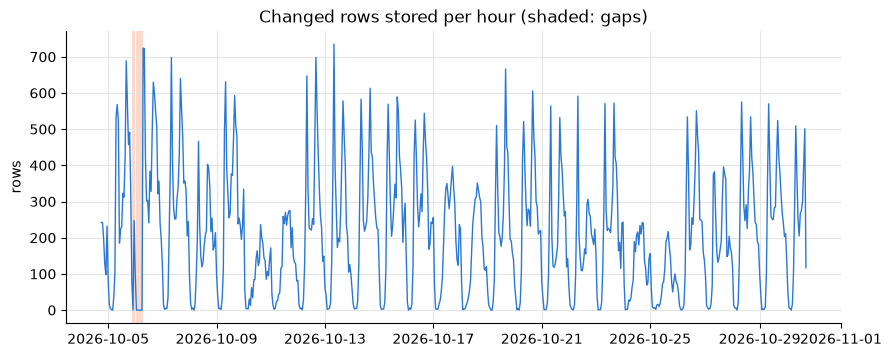

In [5]:
rows_per_hour = (
    status.set_index("fetched_at")
    .sort_index()
    .tz_convert(OSLO)
    .loc[ANALYSIS_START:]
    .resample("1h")
    .size()
)
fig, ax = plt.subplots()
ax.plot(rows_per_hour.index, rows_per_hour.to_numpy(), color=BLUE, linewidth=1)
for _, g in gaps.iterrows():
    ax.axvspan(g["start"], g["end"], color=ORANGE, alpha=0.25, linewidth=0)
ax.set_title("Changed rows stored per hour (shaded: gaps)")
ax.set_ylabel("rows")
plt.show()

The nightly dips are quiet hours, not outages: almost nothing changes, so almost
nothing is stored.

## 2. Data quality checks

In [6]:
last_row = status.groupby("station_id")["fetched_at"].max()
stale = last_row[last_row < status["fetched_at"].max() - pd.Timedelta("3D")]
print(f"Stations with no change in the last 3 days: {len(stale)}")

assert (status["num_ebikes_available"] <= status["num_bikes_available"]).all(), (
    "ebikes should be a subset of num_bikes_available"
)
print("E-bikes are included in num_bikes_available: OK")

not_active = ~(ok["is_installed"] & ok["is_renting"] & ok["is_returning"])
print(
    f"Slots where a station is not installed/renting/returning: {not_active.mean():.2%}"
)

missing_docks = ok["capacity"] - ok["num_bikes_available"] - ok["num_docks_available"]
print(
    f"Slots where bikes + docks < capacity (disabled docks): {(missing_docks > 0).mean():.1%}"
)
print(f"Slots where bikes + docks > capacity: {(missing_docks < 0).mean():.1%}")

Stations with no change in the last 3 days: 2
E-bikes are included in num_bikes_available: OK
Slots where a station is not installed/renting/returning: 0.33%
Slots where bikes + docks < capacity (disabled docks): 74.4%
Slots where bikes + docks > capacity: 0.0%


## 3. Daily and weekly patterns

Sum of available bikes over all stations. When the total drops, bikes are out on trips
(or removed for rebalancing and charging).

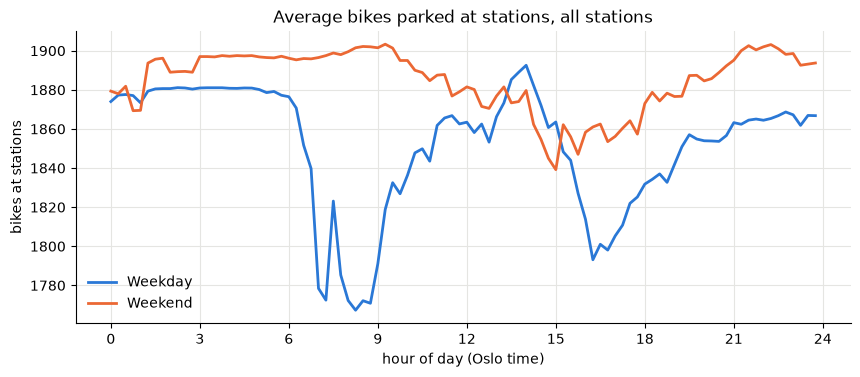

In [7]:
total = ok.groupby("slot").agg(
    bikes=("num_bikes_available", "sum"),
    weekend=("weekend", "first"),
    hour=("hour", "first"),
)
by_hour = total.groupby(["weekend", "hour"])["bikes"].mean().unstack(0)

fig, ax = plt.subplots()
ax.plot(by_hour.index, by_hour[False], color=BLUE, label="Weekday")
ax.plot(by_hour.index, by_hour[True], color=ORANGE, label="Weekend")
ax.set_xticks(range(0, 25, 3))
ax.set_xlabel("hour of day (Oslo time)")
ax.set_ylabel("bikes at stations")
ax.set_title("Average bikes parked at stations, all stations")
ax.legend(frameon=False)
plt.show()

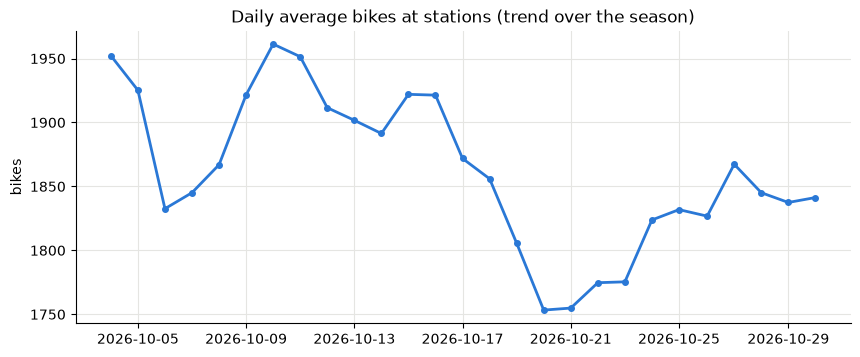

In [8]:
daily = total["bikes"].tz_convert(OSLO).resample("1D").mean()
fig, ax = plt.subplots()
ax.plot(daily.index, daily.to_numpy(), color=BLUE, marker="o", markersize=4)
ax.set_title("Daily average bikes at stations (trend over the season)")
ax.set_ylabel("bikes")
plt.show()

## 4. Differences between stations

Share of active, non-gap time where a station is empty (no bikes) or full (no docks).

In [9]:
active = ok[ok["is_installed"] & ok["is_renting"] & ok["is_returning"]]
per_station = (
    active.groupby(["station_id", "name"])
    .agg(
        capacity=("capacity", "first"),
        mean_bikes=("num_bikes_available", "mean"),
        empty=("num_bikes_available", lambda s: (s == 0).mean()),
        full=("num_docks_available", lambda s: (s == 0).mean()),
    )
    .reset_index()
)

for col in ["empty", "full"]:
    print(f"Stations {col} more than 20% of the time: {(per_station[col] > 0.2).sum()}")
print(f"Overall share of time empty: {(active['num_bikes_available'] == 0).mean():.1%}")
print(f"Overall share of time full:  {(active['num_docks_available'] == 0).mean():.1%}")

Stations empty more than 20% of the time: 76
Stations full more than 20% of the time: 16
Overall share of time empty: 13.6%
Overall share of time full:  4.4%


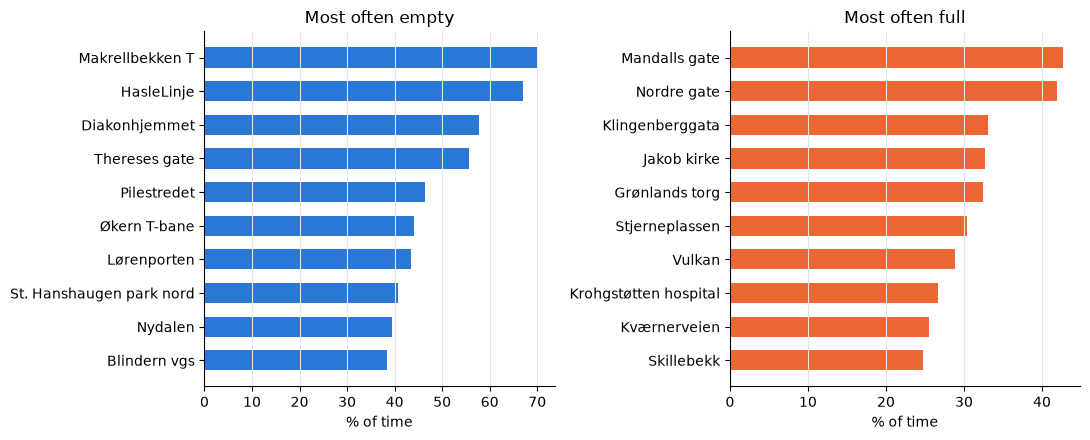

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, col, color, title in [
    (axes[0], "empty", BLUE, "Most often empty"),
    (axes[1], "full", ORANGE, "Most often full"),
]:
    top = per_station.nlargest(10, col).iloc[::-1]
    ax.barh(top["name"], top[col] * 100, color=color, height=0.6)
    ax.set_title(title)
    ax.set_xlabel("% of time")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

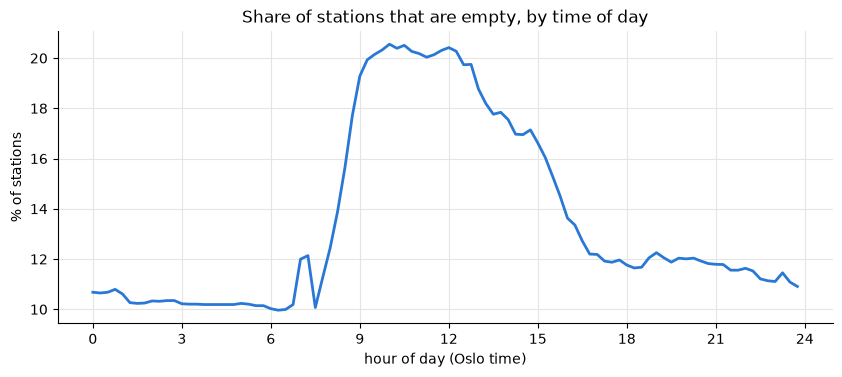

In [11]:
by_hour_station = active.assign(empty=active["num_bikes_available"] == 0)
empty_by_hour = by_hour_station.groupby("hour")["empty"].mean() * 100
fig, ax = plt.subplots()
ax.plot(empty_by_hour.index, empty_by_hour.to_numpy(), color=BLUE)
ax.set_xticks(range(0, 25, 3))
ax.set_xlabel("hour of day (Oslo time)")
ax.set_ylabel("% of stations")
ax.set_title("Share of stations that are empty, by time of day")
plt.show()

## 5. Regular bikes and e-bikes

`num_bikes_available` includes e-bikes, so regular bikes = all bikes − e-bikes.

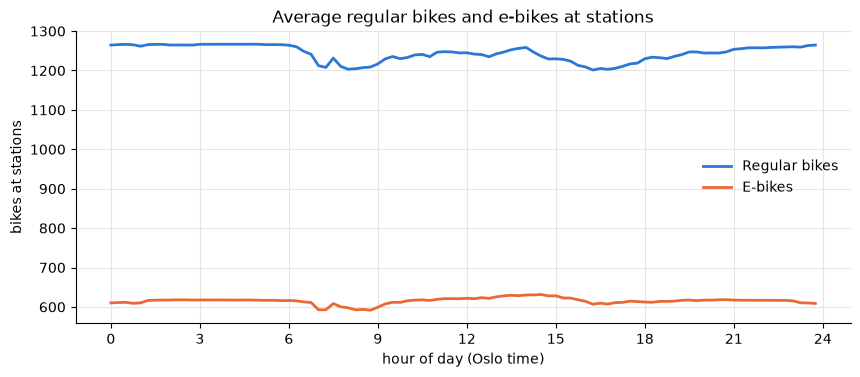

E-bike share of parked bikes: 33.1%
Station-slots with no e-bike:      33.8%
Station-slots with no regular bike: 30.1%


In [17]:
active = active.assign(
    regular=active["num_bikes_available"] - active["num_ebikes_available"]
)
kinds = active.groupby("hour")[["regular", "num_ebikes_available"]].sum()
kinds = kinds / active.groupby("hour")["slot"].nunique().to_numpy()[:, None]

fig, ax = plt.subplots()
ax.plot(kinds.index, kinds["regular"], color=BLUE, label="Regular bikes")
ax.plot(kinds.index, kinds["num_ebikes_available"], color=ORANGE, label="E-bikes")
ax.set_xticks(range(0, 25, 3))
ax.set_xlabel("hour of day (Oslo time)")
ax.set_ylabel("bikes at stations")
ax.set_title("Average regular bikes and e-bikes at stations")
ax.legend(frameon=False)
plt.show()

share_e = active["num_ebikes_available"].sum() / active["num_bikes_available"].sum()
print(f"E-bike share of parked bikes: {share_e:.1%}")
print(
    f"Station-slots with no e-bike:      {(active['num_ebikes_available'] == 0).mean():.1%}"
)
print(f"Station-slots with no regular bike: {(active['regular'] == 0).mean():.1%}")

## 6. How much do the numbers change? (preparation for Phase 3)

For each station and slot, the absolute change in bikes and docks 15, 30 and 60 minutes
later. Pairs where either end is in a gap are skipped. The mean absolute change is exactly
the MAE of the naive "unchanged from now" model, so this is the baseline to beat.

In [13]:
HORIZONS = {"15 min": 1, "30 min": 2, "60 min": 4}
rows = []
changes = {}
by_station = grid.groupby("station_id")
for label, steps in HORIZONS.items():
    for col in ["num_bikes_available", "num_docks_available"]:
        future = by_station[col].shift(-steps)
        diff = (future - grid[col]).abs().astype("float")
        diff = diff[diff.notna()]  # drops gaps and the end of the series
        changes[(label, col)] = diff
        rows.append(
            {
                "horizon": label,
                "target": col.removeprefix("num_").removesuffix("_available"),
                "mean_abs_change": diff.mean(),
                "median": diff.median(),
                "p90": diff.quantile(0.9),
                "unchanged": (diff == 0).mean(),
            }
        )
change_table = pd.DataFrame(rows)
change_table.round(3)

,horizon,target,mean_abs_change,median,p90,unchanged
0,15 min,bikes,0.250,0.0,1.0,0.828
1,15 min,docks,0.247,0.0,1.0,0.829
2,30 min,bikes,0.445,0.0,1.0,0.729
3,30 min,docks,0.440,0.0,1.0,0.731
4,60 min,bikes,0.748,0.0,2.0,0.622
5,60 min,docks,0.745,0.0,2.0,0.622


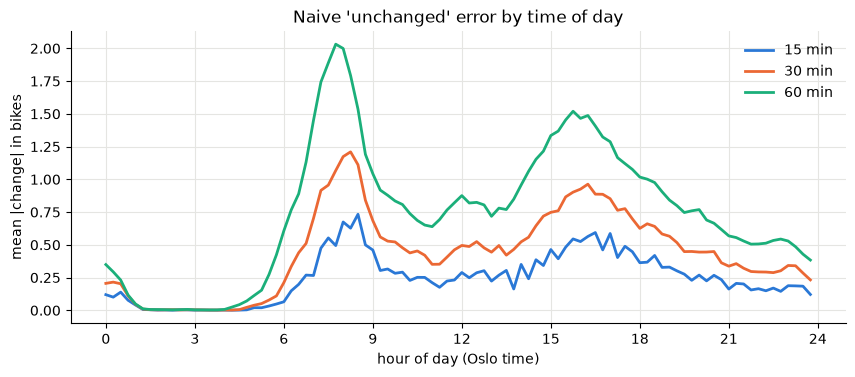

In [14]:
fig, ax = plt.subplots()
for label, color in zip(HORIZONS, [BLUE, ORANGE, "#1baf7a"], strict=True):
    diff = changes[(label, "num_bikes_available")]
    mae = diff.groupby(grid.loc[diff.index, "hour"]).mean()
    ax.plot(mae.index, mae.to_numpy(), color=color, label=label)
ax.set_xticks(range(0, 25, 3))
ax.set_xlabel("hour of day (Oslo time)")
ax.set_ylabel("mean |change| in bikes")
ax.set_title("Naive 'unchanged' error by time of day")
ax.legend(frameon=False)
plt.show()

## Summary numbers

Printed together so they can be copied into `docs/findings.md`.

In [15]:
print(
    f"Period: {grid['local'].min():%Y-%m-%d} to {grid['local'].max():%Y-%m-%d}, "
    f"{grid['station_id'].nunique()} stations"
)
print(f"Gap slots: {slots['is_gap'].mean():.1%}; stale stations: {len(stale)}")
print(
    f"Time empty: {(active['num_bikes_available'] == 0).mean():.1%}, "
    f"full: {(active['num_docks_available'] == 0).mean():.1%}"
)
print(
    f"Stations empty >20%: {(per_station['empty'] > 0.2).sum()}, "
    f"full >20%: {(per_station['full'] > 0.2).sum()}"
)
print(f"E-bike share: {share_e:.1%}")
peak_wd = by_hour[False].idxmin()
peak_we = by_hour[True].idxmin()
print(f"Fewest parked bikes: weekday {peak_wd:.2f}h, weekend {peak_we:.2f}h (Oslo)")
print(
    f"Daily average bikes, first vs last day: {daily.iloc[0]:.0f} -> {daily.iloc[-1]:.0f}"
)
print(change_table.round(2).to_string(index=False))

Period: 2026-10-04 to 2026-10-30, 267 stations
Gap slots: 1.3%; stale stations: 2
Time empty: 13.6%, full: 4.4%
Stations empty >20%: 76, full >20%: 16
E-bike share: 33.1%
Fewest parked bikes: weekday 8.25h, weekend 15.00h (Oslo)
Daily average bikes, first vs last day: 1952 -> 1841
horizon target  mean_abs_change  median  p90  unchanged
 15 min  bikes             0.25     0.0  1.0       0.83
 15 min  docks             0.25     0.0  1.0       0.83
 30 min  bikes             0.44     0.0  1.0       0.73
 30 min  docks             0.44     0.0  1.0       0.73
 60 min  bikes             0.75     0.0  2.0       0.62
 60 min  docks             0.75     0.0  2.0       0.62
